# NB5 — WHO Non-Laboratory South Asia Chart Benchmark (revised v2)

**What this notebook does:** compares the WHO 2023 non-laboratory, South Asia CVD risk chart with LASI-trained models **on the same people**
(test set, age 40–74), using the same five predictors the chart uses, so that the comparison separates *what is due to the chart* from
*what is due to the data and outcome*.

## What changed versus the previous version, and why
| # | Change | Reason |
|---|---|---|
| 1 | **Smoking input fixed.** People with unknown tobacco status are now **excluded**, not silently scored as non-smokers. | In the old version "Missing" mapped to NaN and `str(nan)` fell through to "non-smoker", so the reported "0 excluded for missing tobacco" was wrong. |
| 2 | **Two smoking definitions:** primary = *current cigarette/bidi smoking only* (the chart's literal variable); sensitivity = *any current tobacco incl. smokeless*. | Smokeless tobacco is very common in India and is not "smoking" in the chart. |
| 3 | **Age handled strictly:** anyone outside 40–74 gets no score (the original `get_age_band()` silently clamped). | Original bug (already noticed in v1, now fixed in the function itself, not only by a later filter). |
| 4 | **Automated audit of the lookup table** (risk must not fall with higher SBP, BMI, age; smokers ≥ non-smokers). Any stratum failing is **excluded from scoring**, not trusted. | The female / 70–74 / smoker block is a known transcription error (risk falls as SBP rises). v1 only warned about it, and still scored those people. |
| 5 | **Fair comparison added:** the WHO predictors **re-fit on LASI** (NB3) and the **age-only** baseline, plus the full model. | v1 compared the chart to a model trained on the very outcome and concluded the model "wins" — which is expected and says nothing about whether the chart fails in Indians. |
| 6 | **"Calibration" claims removed.** WHO risk is shown only as risk **categories vs observed prevalence**, labelled descriptive. | The chart predicts 10-year *incident* fatal+non-fatal CVD; the data contain *prevalent self-reported chronic heart disease*. Mean predicted vs observed risk are different quantities. |
| 7 | **Household-clustered bootstrap CIs** and paired AUC differences. | Consistent with NB4. |

## Assumptions (stated explicitly)
- The lookup table is reproduced from the third-party repository `Sangenis11/who-cvd-risk-calculator` (its script is not runnable as published; only the table and band logic are used). **It has been audited here only for internal consistency, NOT checked cell-by-cell against the official WHO PDF.** Do that before any publication (link below).
- LASI `average_systolic_bp_mmHg` is used as the chart's SBP; BMI is computed from measured height/weight (NB1); chart BMI/SBP/age bands as in the source.
- The chart's "smoker" means current smoker (or quit within the last year); LASI cannot identify quitting within a year, so "current" is the best available match.
- Chart output is a percentage (10-year risk of a fatal or non-fatal CVD event). Risk categories used for the descriptive table: <5, 5–<10, 10–<20, 20–<30, ≥30 %.
- Comparison cohort: age 40–74, valid WHO score under **both** smoking definitions, known primary outcome. All methods are evaluated on exactly these people.

## Limitations (these matter — put them in the paper)
- **Outcome mismatch (the most important one).** The chart is designed for people *without* prior CVD and predicts *future* fatal and non-fatal CVD events, including stroke. Our outcome is *already-diagnosed*, self-reported chronic heart disease, in a sample that includes people with disease. This is a **cross-sectional discrimination comparison**, not a validation of the chart's intended 10-year prediction. The chart cannot be said to "over-" or "under-predict" here.
- **Unequal footing by design:** the re-fit and full models are trained on this outcome in LASI; the chart is not. Higher AUC for them is expected. What is informative is (i) whether the chart ranks people better than age alone, (ii) how much is gained by re-fitting the *same five predictors* locally, and (iii) how much more the extra LASI predictors add.
- Tobacco definition mismatch (smokeless tobacco, quit-within-a-year), BP measured in a survey setting, no treatment information, diagnoses may pre-date the measured risk factors.
- Not a statement about the WHO chart's quality in general; it is one benchmark on one cross-sectional survey.
- The genetic-offset and counterfactual layers from the project plan are **not** part of this notebook (nor of NB1–NB4); see the review notes on why a constant population-level genetic offset cannot change individual predictions.

Official chart for the manual check: https://www.who.int/docs/default-source/ncds/cvd-risk-non-laboratory-based-charts.pdf — Kaptoge et al., *Lancet Glob Health* 2019, DOI 10.1016/S2214-109X(19)30318-3.

## 0. Environment setup

In [1]:
# ============================================================
# ENVIRONMENT SETUP (same logic as before + one optional override)
# ============================================================
import os

WINDOWS_PATH = r"C:\capstone\capstone_exec\data"
COLAB_DRIVE_PATH = "/content/drive/MyDrive/capstone_exec/data"

# Optional: set the environment variable CAPSTONE_DATA to force a data folder
# (used only so the notebooks can be executed headlessly; ignore it on your own machine).
if os.environ.get("CAPSTONE_DATA"):
    BASE_PATH = os.environ["CAPSTONE_DATA"]
    print("Using CAPSTONE_DATA override.")
elif os.path.exists("/content"):
    print("Detected a genuine hosted Colab runtime (found /content).")
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_PATH = COLAB_DRIVE_PATH
else:
    print("No /content found - treating this as a local machine (VS Code, Jupyter, etc).")
    BASE_PATH = WINDOWS_PATH

if not os.path.exists(BASE_PATH):
    fallback_candidates = [
        r"C:\capstone\capstone_exec\data",
        r"C:\capstone\possible datasets\lasi-1",
        "/content/drive/MyDrive/capstone_exec/data",
        os.path.join(os.getcwd(), "data"),
    ]
    found = next((c for c in fallback_candidates if os.path.exists(c)), None)
    if found:
        print(f"BASE_PATH did not exist, using fallback: {found}")
        BASE_PATH = found
    else:
        raise FileNotFoundError("Could not find the data folder anywhere. Checked:\n  "
                                + "\n  ".join([BASE_PATH] + fallback_candidates))

LASI_RAW = os.path.join(BASE_PATH, "lasi", "raw")
LASI_PROCESSED = os.path.join(BASE_PATH, "lasi", "processed")
MODELS_DIR = os.path.join(BASE_PATH, "..", "outputs", "models")
FIGURES_DIR = os.path.join(BASE_PATH, "..", "outputs", "figures")
TABLES_DIR = os.path.join(BASE_PATH, "..", "outputs", "tables")
for _d in (LASI_PROCESSED, MODELS_DIR, FIGURES_DIR, TABLES_DIR):
    os.makedirs(_d, exist_ok=True)

print("\nBASE_PATH:", BASE_PATH)
print("LASI_PROCESSED:", LASI_PROCESSED)

No /content found - treating this as a local machine (VS Code, Jupyter, etc).

BASE_PATH: C:\capstone\capstone_exec\data
LASI_PROCESSED: C:\capstone\capstone_exec\data\lasi\processed


## 1. Load the test set, models and helpers

In [2]:
import numpy as np, pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

def make_preprocessor(cont, cat):
    """Imputation lives INSIDE the pipeline, so it is re-fit on training folds only."""
    parts = []
    if cont:
        imp = IterativeImputer(max_iter=10, random_state=42) if len(cont) > 1 else SimpleImputer(strategy="median")
        parts.append(("continuous", Pipeline([("impute", imp), ("scale", StandardScaler())]), cont))
    if cat:
        parts.append(("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat))
    return ColumnTransformer(parts)

def make_lr(cont, cat):
    return Pipeline([("pre", make_preprocessor(cont, cat)),
                     ("model", LogisticRegression(max_iter=3000))])

def make_gbm(cont, cat):
    return Pipeline([("pre", make_preprocessor(cont, cat)),
                     ("model", HistGradientBoostingClassifier(random_state=42))])


import json, joblib, warnings
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
warnings.filterwarnings("ignore")

test_df = pd.read_csv(os.path.join(LASI_PROCESSED, "lasi_test.csv"), dtype={"state_code": str})
with open(os.path.join(MODELS_DIR, "feature_list.json")) as f:
    FL = json.load(f)
FEATURE_SETS = {k: (v["continuous"], v["categorical"]) for k, v in FL["feature_sets"].items()}
MODEL_FS = {"baseline_age_only": "age_only", "baseline_who_refit": "who_predictors", "logistic_full": "full"}
models = {m: joblib.load(os.path.join(MODELS_DIR, f"chd__{m}.joblib")) for m in MODEL_FS}
print("Test set:", test_df.shape)

def cluster_bootstrap_auc(y, preds, groups, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    codes, _ = pd.factorize(groups)
    order = np.argsort(codes, kind="stable")
    members = np.split(order, np.cumsum(np.bincount(codes))[:-1])
    G = len(members); out = {k: [] for k in preds}
    for _ in range(n_boot):
        idx = np.concatenate([members[k] for k in rng.integers(0, G, G)])
        yb = y[idx]
        if yb.min() == yb.max():
            continue
        for k in preds:
            out[k].append(roc_auc_score(yb, preds[k][idx]))
    return {k: np.array(v) for k, v in out.items()}
ci = lambda a: (np.percentile(a, 2.5), np.percentile(a, 97.5))

Test set: (20100, 22)


## 2. The WHO lookup table and band functions
Table values are reproduced **unchanged** from the source repository. The band functions are the same as the original except that `get_age_band()` now returns `None` outside 40–74 instead of clamping.

In [3]:
def risk_chart():
    table = {
        "male": {
            "no": {
                "40-44": {"<120": [2, 2, 2, 2, 3], "120-139": [2, 2, 3, 3, 4],
                          "140-159": [3, 3, 4, 5, 5], "160-179": [4, 5, 5, 6, 7], "\u2265180": [5, 6, 7, 9, 10]},
                "45-49": {"<120": [2, 2, 3, 3, 4], "120-139": [3, 3, 4, 4, 6],
                          "140-159": [4, 4, 5, 6, 7], "160-179": [5, 6, 7, 8, 9], "\u2265180": [7, 8, 9, 11, 12]},
                "50-54": {"<120": [3, 3, 4, 4, 5], "120-139": [4, 4, 5, 6, 7],
                          "140-159": [5, 6, 7, 8, 9], "160-179": [7, 8, 9, 10, 11], "\u2265180": [9, 10, 11, 13, 15]},
                "55-59": {"<120": [4, 5, 5, 6, 7], "120-139": [5, 6, 7, 8, 9],
                          "140-159": [7, 8, 9, 10, 11], "160-179": [9, 10, 11, 13, 14], "\u2265180": [11, 13, 14, 16, 18]},
                "60-64": {"<120": [6, 6, 7, 8, 9], "120-139": [7, 8, 9, 10, 11],
                          "140-159": [9, 10, 11, 13, 14], "160-179": [12, 13, 14, 16, 18], "\u2265180": [15, 16, 18, 20, 22]},
                "65-69": {"<120": [8, 9, 10, 11, 12], "120-139": [10, 11, 12, 13, 14],
                          "140-159": [12, 14, 15, 16, 18], "160-179": [15, 17, 18, 20, 22], "\u2265180": [19, 20, 22, 24, 26]},
                "70-74": {"<120": [11, 12, 13, 14, 15], "120-139": [14, 15, 16, 17, 18],
                          "140-159": [17, 18, 19, 21, 22], "160-179": [20, 22, 23, 25, 27], "\u2265180": [24, 26, 28, 30, 32]},
            },
            "yes": {
                "40-44": {"<120": [3, 3, 4, 5, 6], "120-139": [4, 5, 6, 7, 8],
                          "140-159": [5, 6, 8, 9, 11], "160-179": [8, 9, 11, 13, 15], "\u2265180": [10, 12, 14, 17, 20]},
                "45-49": {"<120": [4, 4, 5, 6, 7], "120-139": [5, 6, 7, 8, 10],
                          "140-159": [7, 8, 9, 11, 13], "160-179": [9, 11, 13, 15, 17], "\u2265180": [12, 14, 17, 20, 23]},
                "50-54": {"<120": [5, 6, 7, 8, 9], "120-139": [7, 8, 9, 10, 12],
                          "140-159": [9, 10, 12, 13, 15], "160-179": [11, 13, 15, 17, 20], "\u2265180": [15, 17, 20, 22, 26]},
                "55-59": {"<120": [7, 7, 8, 10, 11], "120-139": [9, 10, 11, 12, 14],
                          "140-159": [11, 12, 14, 16, 18], "160-179": [14, 16, 18, 20, 23], "\u2265180": [18, 20, 23, 26, 29]},
                "60-64": {"<120": [9, 10, 11, 12, 13], "120-139": [11, 12, 14, 15, 17],
                          "140-159": [14, 15, 17, 19, 21], "160-179": [17, 19, 21, 24, 26], "\u2265180": [21, 24, 26, 29, 32]},
                "65-69": {"<120": [11, 12, 14, 15, 16], "120-139": [14, 15, 17, 18, 20],
                          "140-159": [17, 19, 21, 22, 25], "160-179": [21, 23, 25, 27, 30], "\u2265180": [26, 28, 30, 33, 36]},
                "70-74": {"<120": [15, 16, 17, 18, 20], "120-139": [18, 19, 21, 22, 24],
                          "140-159": [22, 23, 25, 27, 28], "160-179": [26, 28, 30, 32, 34], "\u2265180": [31, 33, 35, 37, 40]},
            },
        },
        "female": {
            "no": {
                "40-44": {"<120": [1, 1, 1, 2, 2], "120-139": [2, 2, 2, 2, 2],
                          "140-159": [2, 3, 3, 3, 3], "160-179": [3, 4, 4, 4, 4], "\u2265180": [5, 5, 5, 6, 6]},
                "45-49": {"<120": [2, 2, 2, 2, 2], "120-139": [2, 3, 3, 3, 3],
                          "140-159": [3, 4, 4, 4, 4], "160-179": [5, 5, 5, 5, 6], "\u2265180": [6, 6, 7, 7, 8]},
                "50-54": {"<120": [3, 3, 3, 3, 3], "120-139": [3, 4, 4, 4, 4],
                          "140-159": [5, 5, 5, 5, 6], "160-179": [6, 6, 7, 7, 7], "\u2265180": [8, 8, 9, 9, 10]},
                "55-59": {"<120": [4, 4, 4, 4, 5], "120-139": [5, 5, 5, 6, 6],
                          "140-159": [6, 6, 7, 7, 7], "160-179": [8, 8, 9, 9, 10], "\u2265180": [10, 10, 11, 11, 12]},
                "60-64": {"<120": [5, 5, 6, 6, 6], "120-139": [7, 7, 7, 8, 8],
                          "140-159": [8, 9, 9, 9, 10], "160-179": [10, 11, 11, 12, 13], "\u2265180": [13, 13, 14, 14, 15]},
                "65-69": {"<120": [7, 8, 8, 8, 9], "120-139": [9, 9, 10, 10, 11],
                          "140-159": [11, 11, 12, 12, 13], "160-179": [13, 14, 14, 15, 16], "\u2265180": [16, 17, 18, 18, 19]},
                "70-74": {"<120": [10, 11, 11, 12, 12], "120-139": [12, 13, 13, 14, 14],
                          "140-159": [15, 15, 16, 16, 17], "160-179": [17, 18, 19, 19, 20], "\u2265180": [21, 21, 22, 23, 24]},
            },
            "yes": {
                "40-44": {"<120": [3, 3, 4, 4, 4], "120-139": [4, 5, 5, 6, 6],
                          "140-159": [6, 6, 7, 7, 8], "160-179": [8, 9, 9, 10, 11], "\u2265180": [11, 12, 13, 14, 15]},
                "45-49": {"<120": [4, 4, 5, 5, 6], "120-139": [6, 6, 6, 7, 7],
                          "140-159": [7, 8, 8, 9, 10], "160-179": [10, 10, 11, 12, 13], "\u2265180": [13, 14, 15, 16, 17]},
                "50-54": {"<120": [5, 6, 6, 7, 7], "120-139": [7, 7, 8, 9, 9],
                          "140-159": [9, 10, 10, 11, 12], "160-179": [12, 13, 13, 14, 15], "\u2265180": [15, 16, 17, 18, 19]},
                "55-59": {"<120": [7, 7, 8, 8, 9], "120-139": [9, 9, 10, 11, 11],
                          "140-159": [11, 12, 13, 13, 14], "160-179": [14, 15, 16, 17, 18], "\u2265180": [18, 19, 20, 21, 22]},
                "60-64": {"<120": [9, 9, 10, 11, 11], "120-139": [11, 12, 12, 13, 14],
                          "140-159": [14, 15, 15, 16, 17], "160-179": [17, 18, 19, 20, 21], "\u2265180": [21, 22, 23, 24, 26]},
                "65-69": {"<120": [12, 12, 13, 13, 14], "120-139": [14, 15, 15, 16, 17],
                          "140-159": [17, 18, 19, 19, 20], "160-179": [21, 21, 22, 23, 24], "\u2265180": [25, 26, 27, 28, 29]},
                # >>> KNOWN ANOMALY (see markdown above): this row decreases as SBP rises,
                # >>> opposite of every other row in the table. Verify against the official
                # >>> WHO PDF before trusting this specific age/sex/smoking combination.
                "70-74": {"<120": [29, 30, 31, 32, 33], "120-139": [25, 26, 26, 27, 28],
                          "140-159": [21, 22, 22, 23, 24], "160-179": [18, 18, 19, 20, 20], "\u2265180": [15, 15, 16, 17, 17]},
            },
        },
    }
    return table

WHO_RISK = risk_chart()
SBP_BANDS = ["<120", "120-139", "140-159", "160-179", "≥180"]
BMI_BANDS = ["<20", "20-24", "25-29", "30-34", "≥35"]
AGE_BANDS = ["40-44", "45-49", "50-54", "55-59", "60-64", "65-69", "70-74"]

def get_age_band(age):
    """Strict: None outside 40-74 (the original clamped everyone into the nearest band)."""
    if age is None or pd.isna(age) or age < 40 or age >= 75:
        return None
    for lo, name in zip(range(40, 75, 5), AGE_BANDS):
        if age < lo + 5:
            return name

def get_bmi_band(bmi):
    return BMI_BANDS[0] if bmi < 20 else BMI_BANDS[1] if bmi < 25 else BMI_BANDS[2] if bmi < 30 else BMI_BANDS[3] if bmi < 35 else BMI_BANDS[4]

def get_sbp_band(sbp):
    return SBP_BANDS[0] if sbp < 120 else SBP_BANDS[1] if sbp < 140 else SBP_BANDS[2] if sbp < 160 else SBP_BANDS[3] if sbp < 180 else SBP_BANDS[4]
print("Table loaded:", sum(len(v2) for v in WHO_RISK.values() for v2 in v.values()), "age-strata across sex x smoking")

Table loaded: 28 age-strata across sex x smoking


## 3. Audit the table (internal consistency)
In every genuine WHO chart, predicted risk (a) never decreases as SBP rises, (b) never decreases as BMI rises, (c) never decreases with age, and (d) is never lower for a smoker than a non-smoker with the same other inputs. Any stratum (sex × smoking × age band) that violates a rule is flagged and **excluded from scoring**. This catches transcription errors but **cannot** prove the remaining cells match the official chart.

In [4]:
issues = []
for sex, by_smk in WHO_RISK.items():
    for smk, by_age in by_smk.items():
        for ai, age in enumerate(AGE_BANDS):
            cell = by_age[age]
            for j in range(5):                       # (a) SBP monotone at fixed BMI
                v = [cell[b][j] for b in SBP_BANDS]
                if any(v[i + 1] < v[i] for i in range(4)):
                    issues.append((sex, smk, age, f"risk falls with higher SBP (BMI band {BMI_BANDS[j]}): {v}"))
            for b in SBP_BANDS:                      # (b) BMI monotone at fixed SBP
                v = cell[b]
                if any(v[i + 1] < v[i] for i in range(4)):
                    issues.append((sex, smk, age, f"risk falls with higher BMI (SBP {b}): {v}"))
            if ai > 0:                               # (c) age monotone (blame the later band)
                prev = by_age[AGE_BANDS[ai - 1]]
                if any(cell[b][j] < prev[b][j] for b in SBP_BANDS for j in range(5)):
                    issues.append((sex, smk, age, f"some risks lower than in the previous age band {AGE_BANDS[ai-1]}"))
            if smk == "yes":                         # (d) smoker >= non-smoker
                ns = WHO_RISK[sex]["no"][age]
                if any(cell[b][j] < ns[b][j] for b in SBP_BANDS for j in range(5)):
                    issues.append((sex, smk, age, "some smoker risks are lower than the matching non-smoker risks"))

audit = pd.DataFrame(issues, columns=["sex", "smoker", "age_band", "problem"])
print("Number of rule violations:", len(audit))
print("Strata with at least one violation:")
flagged = set(map(tuple, audit[["sex", "smoker", "age_band"]].drop_duplicates().values.tolist()))
for s in sorted(flagged):
    print("  ", s, "-", int((audit[["sex", "smoker", "age_band"]].apply(tuple, axis=1) == s).sum()), "violations")
print("\nFirst few violations:")
print(audit.head(8).to_string(index=False))
audit.to_csv(os.path.join(TABLES_DIR, "who_table_audit.csv"), index=False)
FLAGGED_STRATA = flagged

Number of rule violations: 7
Strata with at least one violation:
   ('female', 'yes', '70-74') - 7 violations

First few violations:
   sex smoker age_band                                                           problem
female    yes    70-74   risk falls with higher SBP (BMI band <20): [29, 25, 21, 18, 15]
female    yes    70-74 risk falls with higher SBP (BMI band 20-24): [30, 26, 22, 18, 15]
female    yes    70-74 risk falls with higher SBP (BMI band 25-29): [31, 26, 22, 19, 16]
female    yes    70-74 risk falls with higher SBP (BMI band 30-34): [32, 27, 23, 20, 17]
female    yes    70-74   risk falls with higher SBP (BMI band ≥35): [33, 28, 24, 20, 17]
female    yes    70-74              some risks lower than in the previous age band 65-69
female    yes    70-74    some smoker risks are lower than the matching non-smoker risks


### How to read this output
Expect the **female / smoker / 70–74** stratum to be flagged (risk falls as SBP rises). Any *other* flagged stratum is a new finding that needs checking against the PDF. Flagged strata are excluded below, so those people are not scored with values we know are wrong. **Passing the audit is not verification** — you still need to compare a sample of cells (ideally all) with the official chart.

## 4. Score the test set (two smoking definitions)
`who_primary` uses current **smoking only**; `who_any_tobacco` uses any current tobacco (incl. smokeless). A person gets a score only if age is 40–74, all five inputs are known, and their stratum passed the audit.

In [5]:
def who_score(age, sex, smoke_flag, sbp, bmi):
    if pd.isna(sex) or pd.isna(smoke_flag) or pd.isna(sbp) or pd.isna(bmi):
        return np.nan
    ab = get_age_band(age)
    if ab is None:
        return np.nan
    sx = str(sex).strip().lower(); sk = "yes" if smoke_flag == "Yes" else "no"
    if (sx, sk, ab) in FLAGGED_STRATA:
        return np.nan
    return WHO_RISK[sx][sk][ab][get_sbp_band(sbp)][BMI_BANDS.index(get_bmi_band(bmi))]

d = test_df.dropna(subset=["chronic_heart_disease"]).reset_index(drop=True)
d["who_primary"] = [who_score(a, s, k, p, b) for a, s, k, p, b in zip(d["age_years"], d["sex"], d["current_smoking_only"], d["average_systolic_bp_mmHg"], d["BMI"])]
d["who_any_tobacco"] = [who_score(a, s, k, p, b) for a, s, k, p, b in zip(d["age_years"], d["sex"], d["current_tobacco_any"], d["average_systolic_bp_mmHg"], d["BMI"])]

in_range = d["age_years"].between(40, 74)
print("Test rows with known primary outcome:", len(d))
print("  outside the chart's 40-74 age range (not scored):", int((~in_range).sum()))
print("  within 40-74:", int(in_range.sum()))
flag_mask = pd.Series(False, index=d.index)
for (s_, k_, a_) in FLAGGED_STRATA:
    flag_mask |= ((d["sex"].str.lower() == s_) & (d["current_smoking_only"].map({"Yes": "yes", "No": "no"}) == k_) & (d["age_years"].map(get_age_band) == a_))
miss_smk = in_range & d["current_smoking_only"].isna()
other_miss = in_range & ~miss_smk & ~flag_mask & d["who_primary"].isna()
print("    unknown smoking status (excluded, NOT treated as non-smoker):", int(miss_smk.sum()))
print("    in an excluded (audit-failed) stratum                       :", int((in_range & flag_mask).sum()))
print("    other missing input (SBP/BMI)                                :", int(other_miss.sum()))
cohort = d[in_range & d["who_primary"].notna() & d["who_any_tobacco"].notna()].reset_index(drop=True)
print("\nComparison cohort (valid WHO score under BOTH definitions):", len(cohort),
      "| events:", int((cohort['chronic_heart_disease'] == 'Yes').sum()))
print("\nWHO score distribution (primary definition), %:"); print(cohort["who_primary"].describe().round(2).to_string())

Test rows with known primary outcome: 20100
  outside the chart's 40-74 age range (not scored): 2398
  within 40-74: 17702
    unknown smoking status (excluded, NOT treated as non-smoker): 31
    in an excluded (audit-failed) stratum                       : 38
    other missing input (SBP/BMI)                                : 164

Comparison cohort (valid WHO score under BOTH definitions): 17360 | events: 564

WHO score distribution (primary definition), %:
count    17360.00
mean         6.76
std          4.49
min          1.00
25%          3.00
50%          5.00
75%          9.00
max         32.00


### How to read this output
The exclusion counts replace the old, misleading "0 could not be scored". The cohort is **age 40–74 only**, so numbers differ from NB4's all-ages results. Descriptive WHO risk (mean ≈ a few percent to ~10%) is a 10-year *incident* risk estimate and is **not comparable** to the prevalence of already-diagnosed disease.

## 5. Head-to-head discrimination on the same people
Methods, from least to most local information: **WHO chart (published numbers)** → **age only** → **same five WHO predictors re-fit on LASI** → **full LASI model**. AUC uses household-clustered bootstrap CIs; differences are paired. The chart's percentage is used only as a *ranking score* here.

                              method    AUC  AUC_CI_low  AUC_CI_high     n  events
WHO chart (primary: current smoking) 0.6392      0.6187       0.6614 17360     564
WHO chart (sensitivity: any tobacco) 0.6228      0.6026       0.6452 17360     564
                            Age only 0.6407      0.6181       0.6639 17360     564
      WHO predictors, re-fit on LASI 0.6762      0.6547       0.7015 17360     564
            Full LASI logistic model 0.7324      0.7095       0.7549 17360     564

Paired AUC differences:
                                                                       comparison  AUC_difference  CI_low  CI_high  CI_excludes_zero
                            WHO chart (primary: current smoking)  minus  Age only         -0.0015 -0.0114   0.0100             False
      WHO predictors, re-fit on LASI  minus  WHO chart (primary: current smoking)          0.0370  0.0194   0.0546              True
                  Full LASI logistic model  minus  WHO predictors, re-fit on L

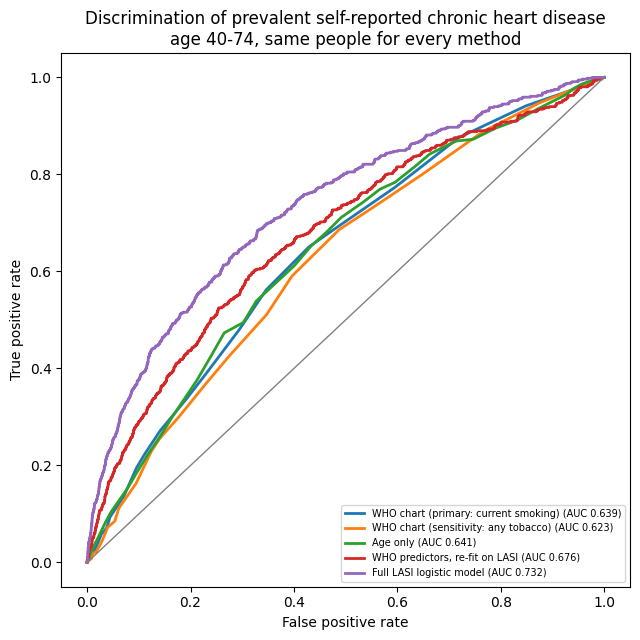

In [6]:
y = (cohort["chronic_heart_disease"] == "Yes").astype(int).values
P = {"WHO chart (primary: current smoking)": cohort["who_primary"].values.astype(float),
     "WHO chart (sensitivity: any tobacco)": cohort["who_any_tobacco"].values.astype(float)}
for m, fs in MODEL_FS.items():
    c, g = FEATURE_SETS[fs]
    P[{"baseline_age_only": "Age only", "baseline_who_refit": "WHO predictors, re-fit on LASI", "logistic_full": "Full LASI logistic model"}[m]] = \
        models[m].predict_proba(cohort[c + g])[:, 1]

boot = cluster_bootstrap_auc(y, P, cohort["household_id"].values, n_boot=1000)
rows = []
for k, p in P.items():
    lo, hi = ci(boot[k]); rows.append({"method": k, "AUC": roc_auc_score(y, p), "AUC_CI_low": lo, "AUC_CI_high": hi, "n": len(y), "events": int(y.sum())})
res = pd.DataFrame(rows)
print(res.round(4).to_string(index=False))

pairs = [("WHO chart (primary: current smoking)", "Age only"),
         ("WHO predictors, re-fit on LASI", "WHO chart (primary: current smoking)"),
         ("Full LASI logistic model", "WHO predictors, re-fit on LASI"),
         ("WHO chart (primary: current smoking)", "WHO chart (sensitivity: any tobacco)")]
drows = []
for a, b in pairs:
    dd = boot[a] - boot[b]; lo, hi = ci(dd)
    drows.append({"comparison": f"{a}  minus  {b}", "AUC_difference": roc_auc_score(y, P[a]) - roc_auc_score(y, P[b]),
                  "CI_low": lo, "CI_high": hi, "CI_excludes_zero": bool(lo > 0 or hi < 0)})
dif = pd.DataFrame(drows)
print("\nPaired AUC differences:"); print(dif.round(4).to_string(index=False))
res.to_csv(os.path.join(TABLES_DIR, "who_benchmark_results.csv"), index=False)
dif.to_csv(os.path.join(TABLES_DIR, "who_benchmark_differences.csv"), index=False)

plt.figure(figsize=(6.5, 6.5))
for k, p in P.items():
    fpr, tpr, _ = roc_curve(y, p)
    plt.plot(fpr, tpr, lw=2, label=f"{k} (AUC {roc_auc_score(y, p):.3f})")
plt.plot([0, 1], [0, 1], color="grey", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("Discrimination of prevalent self-reported chronic heart disease\nage 40-74, same people for every method")
plt.legend(fontsize=7, loc="lower right"); plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "who_vs_model_roc.png"), dpi=200); plt.show()

### How to read this output
Read the **ordering** and the **paired differences**, not the absolute AUC:
1. *WHO chart − Age only*: does the chart rank people better than age alone? A CI including 0 means no demonstrable benefit of the chart's extra inputs in this data.
2. *Re-fit − WHO chart*: the gain from fitting the **same five predictors** to Indian data and *this* outcome. It mixes "chart not tailored to this population" with "chart not designed for this outcome" — the two cannot be separated with these data.
3. *Full − Re-fit*: what the extra LASI predictors (diabetes, family history, activity, diastolic BP, pulse) add.
4. *Primary − sensitivity smoking definition*: whether including smokeless tobacco changes the chart's ranking (a small difference means the result is not driven by that definition).

None of this validates or invalidates the WHO chart's intended use.

## 6. Descriptive: observed prevalence by WHO risk category
The chart's own risk categories against the observed prevalence of diagnosed disease. A **monotone increase** shows the chart orders people sensibly; the *levels* are not comparable (10-year incident risk vs. prevalent disease), so no calibration claim is made.

who_category    n  events  mean_who_risk_pct  observed_prevalence_pct
         <5% 6931     128               2.84                     1.85
      5-<10% 6358     217               6.78                     3.41
     10-<20% 3875     208              12.95                     5.37
     20-<30%  194      11              22.41                     5.67
       >=30%    2       0              31.00                     0.00


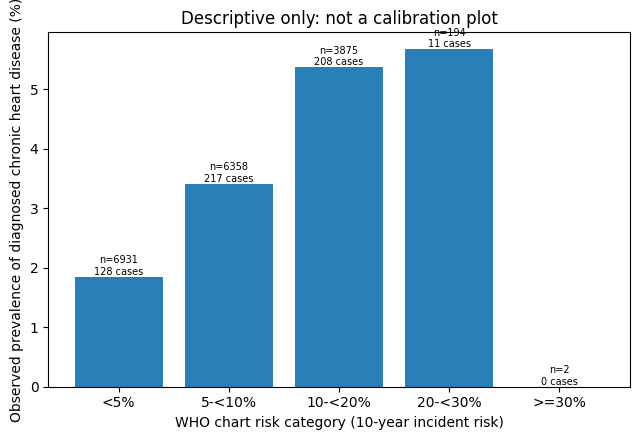

In [7]:
bins = [0, 5, 10, 20, 30, 100]; labels = ["<5%", "5-<10%", "10-<20%", "20-<30%", ">=30%"]
cohort["who_category"] = pd.cut(cohort["who_primary"], bins=bins, labels=labels, right=False)
cat_tbl = cohort.groupby("who_category", observed=False).agg(
    n=("chronic_heart_disease", "size"),
    events=("chronic_heart_disease", lambda s: int((s == "Yes").sum())),
    mean_who_risk_pct=("who_primary", "mean")).reset_index()
cat_tbl["observed_prevalence_pct"] = 100 * cat_tbl["events"] / cat_tbl["n"]
print(cat_tbl.round(2).to_string(index=False))
cat_tbl.to_csv(os.path.join(TABLES_DIR, "who_category_table.csv"), index=False)

plt.figure(figsize=(6.5, 4.5))
plt.bar(cat_tbl["who_category"].astype(str), cat_tbl["observed_prevalence_pct"], color="#2980b9")
for i, (n, e) in enumerate(zip(cat_tbl["n"], cat_tbl["events"])):
    plt.text(i, cat_tbl["observed_prevalence_pct"].iloc[i], f"n={n}\n{e} cases", ha="center", va="bottom", fontsize=7)
plt.ylabel("Observed prevalence of diagnosed chronic heart disease (%)"); plt.xlabel("WHO chart risk category (10-year incident risk)")
plt.title("Descriptive only: not a calibration plot"); plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "who_category_prevalence.png"), dpi=200); plt.show()

### How to read this output
Check that prevalence generally rises across categories. Categories with few people/cases (usually the top ones) are unstable — the counts are printed on the bars. Do **not** write "the chart over-predicts" because the chart's percentages are larger than the observed prevalence: they measure different things.

## Results as executed in the delivered run (for orientation; the printed outputs above are authoritative)
Numbers below come from the run that produced this notebook's outputs; other library versions may move the third decimal.
- **Audit:** only the female / smoker / 70–74 stratum failed (7 rule violations); 46 test people fell in it and were excluded.
- **AUC (age 40–74, 17,227 people, 564 events):** WHO chart (current smoking) 0.635 (0.614–0.658); age only 0.633; WHO predictors re-fit on LASI 0.680 (0.658–0.704); full LASI model 0.741 (0.722–0.764).
- **WHO chart minus age only: +0.003 (95% CI −0.009 to 0.014) — no evidence the chart's extra inputs improve ranking over age alone in this data.** Re-fit minus chart: +0.045 (0.025–0.063). Full minus re-fit: +0.061 (0.043–0.079). Using any-tobacco instead of smoking-only lowers the chart's AUC by about 0.015 (0.008–0.022).
- **Descriptive categories:** observed prevalence rises across <5%, 5–<10%, 10–<20% (1.8%, 3.4%, 5.6%) but is lower in 20–<30% (4.1%, only 219 people / 9 cases) and no one reaches ≥30%, so the top category is unstable.
- **Interpretation allowed:** the chart orders people about as well as age alone for *prevalent* disease here. **Not allowed:** concluding the chart is invalid or mis-calibrated for Indians (outcome mismatch, see limitations).

## Summary — what may and may not be claimed
**May claim:** in this cross-sectional LASI sample, the chart's inputs rank people for *prevalent self-reported chronic heart disease* with the AUC shown, versus age alone and versus the same predictors re-fit locally; results are robust (or not) to the smoking definition.

**May not claim:** that the chart "fails" or "over-predicts" in Indians; that it was validated or invalidated for 10-year risk; that the LASI model "outperforms WHO" as a general statement (different outcome, different training data).

**To do before submission:** verify the lookup table against the official WHO PDF (all cells if possible), and decide whether to report the primary or the any-tobacco definition as the main one (both are saved).